# **Definiendo ruta y direccion del conjunto de mis datos**

In [1]:
%cd "C:\Users\rcard\OneDrive\Desktop\Admin\Cursos\GCI wordl Japon\Competition\Competition"

C:\Users\rcard\OneDrive\Desktop\Admin\Cursos\GCI wordl Japon\Competition\Competition


In [2]:
import os
from pathlib import Path

# Obtener automáticamente el directorio de trabajo actual
current_dir = Path(os.getcwd())

# Definir las rutas de los archivos usando pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Comprobar si las rutas existen
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


# **Cargando paquetes**

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings('ignore')

# **Cargando la data y primeras visualizaciones de la misma**

In [4]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
train.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


In [44]:
sample_sub = pd.read_csv(sample_sub_file)
sample_sub.head()

,SK_ID_CURR,TARGET
0,171202,0.5
1,171203,0.5
2,171204,0.5
3,171205,0.5
4,171206,0.5


# **Creación de mi primer modelo**

Considero la complejidad de trabajar con variables categoricas a la hora de hacer un modelo, entonces para empezar con el trabajo, haré un modelo base con variables numéricas, con el fin de obtener un primer modelo e ir añadiendo las variables categoricas para analizar como interactuan con el nuevo modelo, pero, sin descartar posibles interacciones con las variables categóricas.

In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SK_ID_CURR                  171202 non-null  int64  
 1   NAME_CONTRACT_TYPE          171202 non-null  str    
 2   CODE_GENDER                 171202 non-null  str    
 3   CNT_CHILDREN                171202 non-null  int64  
 4   AMT_INCOME_TOTAL            171202 non-null  float64
 5   AMT_CREDIT                  171202 non-null  float64
 6   AMT_ANNUITY                 171202 non-null  float64
 7   AMT_GOODS_PRICE             171202 non-null  float64
 8   NAME_INCOME_TYPE            171202 non-null  str    
 9   NAME_EDUCATION_TYPE         171202 non-null  str    
 10  NAME_FAMILY_STATUS          171202 non-null  str    
 11  NAME_HOUSING_TYPE           171202 non-null  str    
 12  REGION_POPULATION_RELATIVE  171202 non-null  float64
 13  DAYS_BIRTH               

## Selección de variables

In [6]:
use_features = [
    'CNT_CHILDREN',
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'REGION_POPULATION_RELATIVE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'DAYS_REGISTRATION',
    'DAYS_ID_PUBLISH',
    'OWN_CAR_AGE',
    'CNT_FAM_MEMBERS',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3',
    'DAYS_LAST_PHONE_CHANGE',
    'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR'
]
target = train["TARGET"].values

train = train[use_features]
train["TARGET"] = target
test = test[use_features]

# Comprensión de los datos

### Analizando los valores faltantes de mi conjunto de datos

In [7]:
# Revisar los valores faltantes de los datos de entrenamiento (train)
train.isnull().sum()

CNT_CHILDREN                       0
AMT_INCOME_TOTAL                   0
AMT_CREDIT                         0
AMT_ANNUITY                        0
AMT_GOODS_PRICE                    0
REGION_POPULATION_RELATIVE         0
DAYS_BIRTH                         0
DAYS_EMPLOYED                      0
DAYS_REGISTRATION                  0
DAYS_ID_PUBLISH                    0
OWN_CAR_AGE                   112992
CNT_FAM_MEMBERS                    2
EXT_SOURCE_1                  118928
EXT_SOURCE_2                     369
EXT_SOURCE_3                   54586
DAYS_LAST_PHONE_CHANGE             0
AMT_REQ_CREDIT_BUREAU_HOUR     23116
AMT_REQ_CREDIT_BUREAU_MON      23116
AMT_REQ_CREDIT_BUREAU_QRT      23116
AMT_REQ_CREDIT_BUREAU_YEAR     23116
TARGET                             0
dtype: int64

In [8]:
# Revisar los valores faltantes de los datos de prueba (test)
test.isnull().sum()

CNT_CHILDREN                      0
AMT_INCOME_TOTAL                  0
AMT_CREDIT                        0
AMT_ANNUITY                       0
AMT_GOODS_PRICE                   0
REGION_POPULATION_RELATIVE        0
DAYS_BIRTH                        0
DAYS_EMPLOYED                     0
DAYS_REGISTRATION                 0
DAYS_ID_PUBLISH                   0
OWN_CAR_AGE                   40909
CNT_FAM_MEMBERS                   0
EXT_SOURCE_1                  42912
EXT_SOURCE_2                    130
EXT_SOURCE_3                  19690
DAYS_LAST_PHONE_CHANGE            0
AMT_REQ_CREDIT_BUREAU_HOUR     8513
AMT_REQ_CREDIT_BUREAU_MON      8513
AMT_REQ_CREDIT_BUREAU_QRT      8513
AMT_REQ_CREDIT_BUREAU_YEAR     8513
dtype: int64

In [9]:
def resumen_nulos(train, test):
    # Calcular el porcentaje de nulos usando .mean()
    na_train = train.isnull().mean() * 100
    na_test = test.isnull().mean() * 100
    # Crear un DataFrame comparativo
    df_na = pd.DataFrame({
        '% NA Train': na_train,
        '% NA Test': na_test
    })
    # Filtrar variables que tengan al menos un nulo en train o test
    df_na = df_na[(df_na['% NA Train'] > 0) | (df_na['% NA Test'] > 0)]
    # Ordenar de mayor a menor según el porcentaje de nulos en train
    df_na = df_na.sort_values(by='% NA Train', ascending=False).round(2)
    return df_na

# Ejecución 
tabla_nulos = resumen_nulos(train, test)
print(tabla_nulos.head(20))

                            % NA Train  % NA Test
EXT_SOURCE_1                     69.47      69.78
OWN_CAR_AGE                      66.00      66.52
EXT_SOURCE_3                     31.88      32.02
AMT_REQ_CREDIT_BUREAU_HOUR       13.50      13.84
AMT_REQ_CREDIT_BUREAU_MON        13.50      13.84
AMT_REQ_CREDIT_BUREAU_QRT        13.50      13.84
AMT_REQ_CREDIT_BUREAU_YEAR       13.50      13.84
EXT_SOURCE_2                      0.22       0.21
CNT_FAM_MEMBERS                   0.00       0.00


Dada la importancia de las variables EXT para los modelos XGboost y LigthGBM, y aunque presente un alto número de NA's resulta importante manejar de forma prudente y no borrar de forma directa sin analizar por completo como puede afectar al modelo, en cuanto a la variable OWN_CAR_AGE una suposición muy adecuada es que los valores faltantes aludan a personas que no poseen carro, por lo que hacer una transformación seria lo mas adecuado para tratarla, lo que involucraria crear una variable llamada HAS_CAR. 

In [10]:
train['HAS_CAR'] = np.where(train['OWN_CAR_AGE'].isnull(), 0, 1)
test['HAS_CAR'] = np.where(test['OWN_CAR_AGE'].isnull(), 0, 1)

### Visualización de mis datos

#### Columna Target

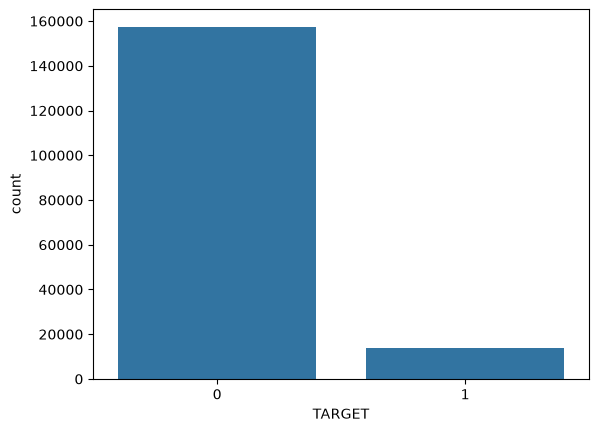

In [11]:
# Distribución del objetivo (incumplimiento o no)
sns.countplot(data=train, x="TARGET")
plt.show()

**Hallazgos**:<br>
* (Posiblemente) hay que pensar en métodos para mitigar el sesgo de la variable objetivo

#### Columnas EXT

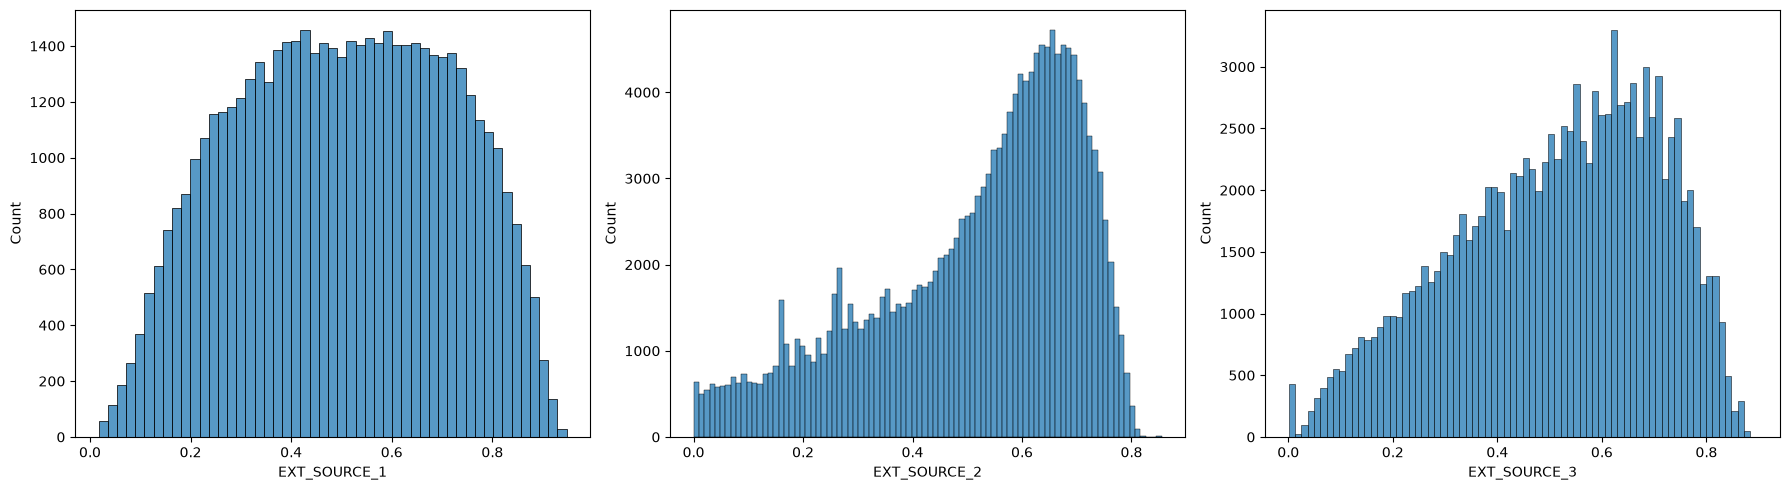

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(data=train, x="EXT_SOURCE_1", ax=axes[0])
sns.histplot(data=train, x="EXT_SOURCE_2", ax=axes[1])
sns.histplot(data=train, x="EXT_SOURCE_3", ax=axes[2])
plt.tight_layout()
plt.show()

#### Columnas AMT
Montos Financieros

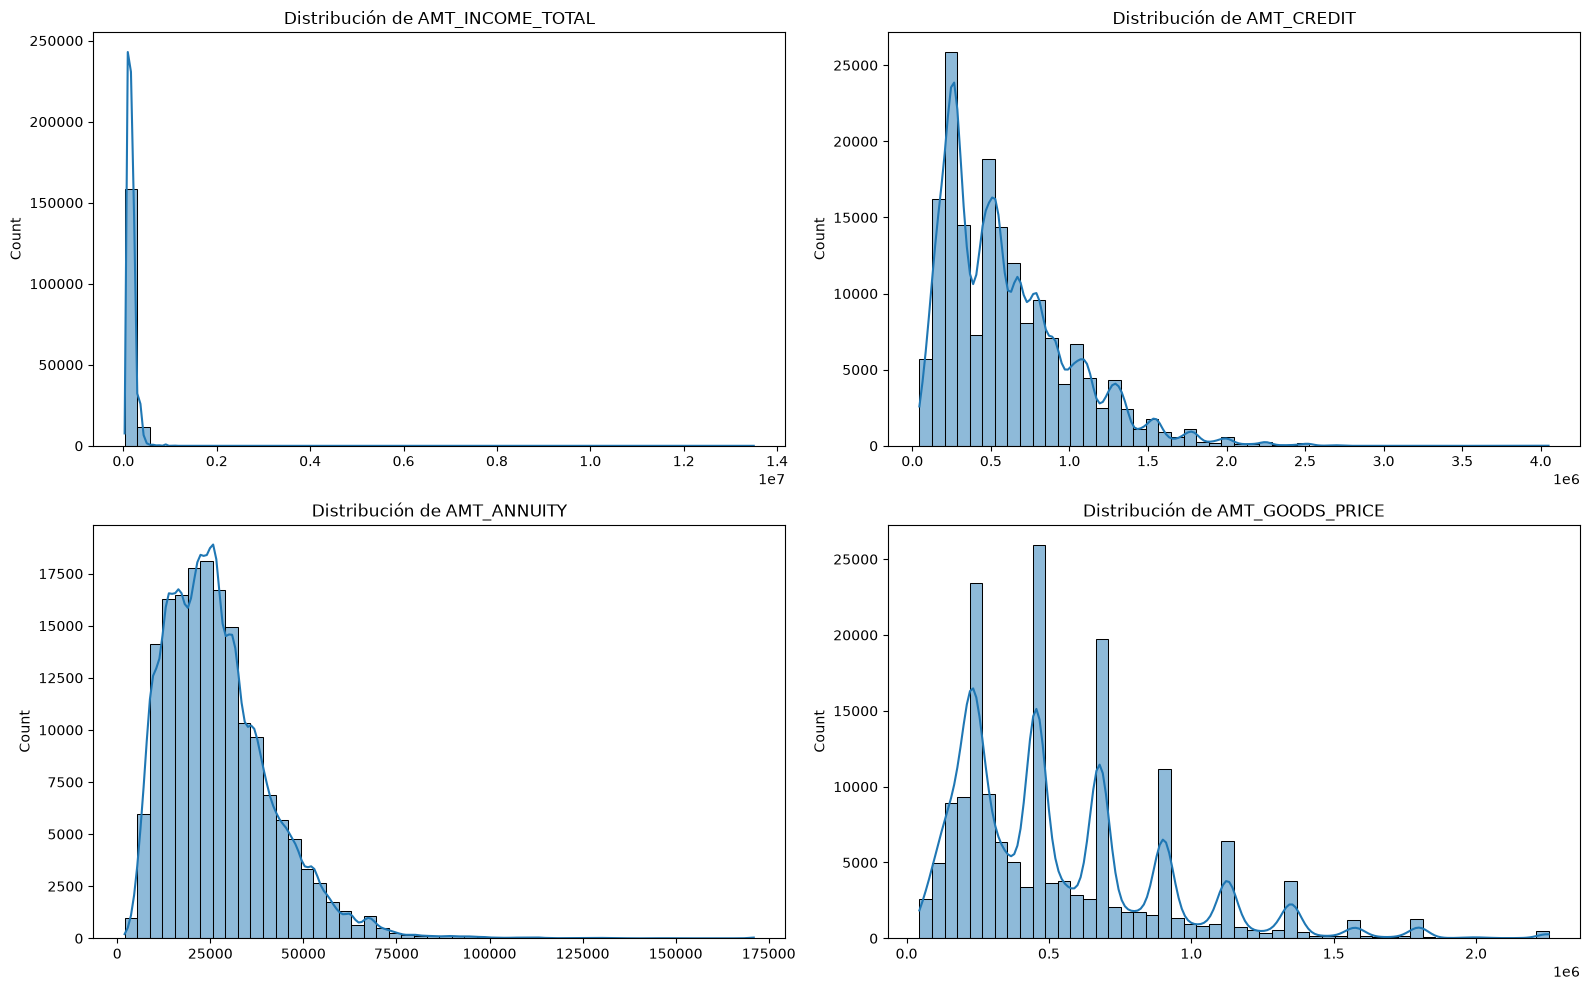

In [13]:
# Lista de variables financieras
cols_amt = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cols_amt):
    sns.histplot(data=train, x=col, bins=50, ax=axes[i], kde=True)
    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

##### Primera observación
Asimetría extrema en los ingresos: La variable AMT_INCOME_TOTAL presenta un sesgo positivo tan severo que la escala del eje X

In [14]:
# Ver los 10 valores más altos de ingresos
print(train['AMT_INCOME_TOTAL'].nlargest(10))

113305    13500000.0
159447     9000000.0
9689       6750000.0
56146      4500000.0
66762      4500000.0
121943     4500000.0
130905     3600000.0
4907       3375000.0
54538      2930026.5
36869      2700000.0
Name: AMT_INCOME_TOTAL, dtype: float64


In [15]:
# Los resultados muestran una escalera de valores extremos, liderada por un ingreso de 13.5 millones, seguido de 9 millones y 6.75 millones. 
# Esto indica que no estás lidiando con un único error absurdo de digitación (como un número de mil millones), sino con un segmento real,
# pero minúsculo, de clientes de muy alto patrimonio.
#Usaremos la técnica de Winsorización
# Ver los límites en los percentiles altos
print("Percentil 99:", train['AMT_INCOME_TOTAL'].quantile(0.99))
print("Percentil 99.9:", train['AMT_INCOME_TOTAL'].quantile(0.999))
# Asignamos el valor del percentil 99.9 como techo (ej. si resulta ser 900,000)
techo_ingresos = train['AMT_INCOME_TOTAL'].quantile(0.999)
# Aplicar el límite a la variable original
train['AMT_INCOME_TOTAL'] = train['AMT_INCOME_TOTAL'].clip(upper=techo_ingresos)
test['AMT_INCOME_TOTAL'] = test['AMT_INCOME_TOTAL'].clip(upper=techo_ingresos)

Percentil 99: 463500.0
Percentil 99.9: 900000.0


#### Segunda observación
AMT_CREDIT y AMT_ANNUITY muestran la clásica asimetría hacia la derecha de las variables financieras. Tienen una concentración clara en los rangos bajos y medios, pero presentan una cola larga de clientes con préstamos y cuotas muy altas.
Además, La relación entre estas variables esconde un fuerte poder predictivo. Aprovechar los montos se crearan nuevas variables que reflejen la salud financiera del cliente (ratios).

In [16]:
# PASO 1: CREAR RATIOS FINANCIEROS (CON VALORES CRUDOS)
# Loan-to-Value (Cuánto pide prestado vs Cuánto cuesta el bien)
train['LTV'] = train['AMT_CREDIT'] / train['AMT_GOODS_PRICE']
test['LTV'] = test['AMT_CREDIT'] / test['AMT_GOODS_PRICE']

# Ratio de Deuda (Qué porcentaje de su ingreso se va en la cuota)
train['DEBT_RATIO'] = train['AMT_ANNUITY'] / train['AMT_INCOME_TOTAL']
test['DEBT_RATIO'] = test['AMT_ANNUITY'] / test['AMT_INCOME_TOTAL']

# PASO 2: APLICAR TRANSFORMACIÓN LOGARÍTMICA
# Lista de variables a suavizar
cols_a_log = ['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'AMT_INCOME_TOTAL']

for col in cols_a_log:
    # Creamos nuevas columnas con el sufijo _LOG
    train[f'{col}_LOG'] = np.log1p(train[col])
    test[f'{col}_LOG'] = np.log1p(test[col])

##### Features para implementar en el modelo :

    'AMT_CREDIT_LOG', 
    'AMT_ANNUITY_LOG', 
    'AMT_GOODS_PRICE_LOG', 
    'AMT_INCOME_TOTAL_LOG',
    'LTV',        
    'DEBT_RATIO'

#### Columnas DAYS

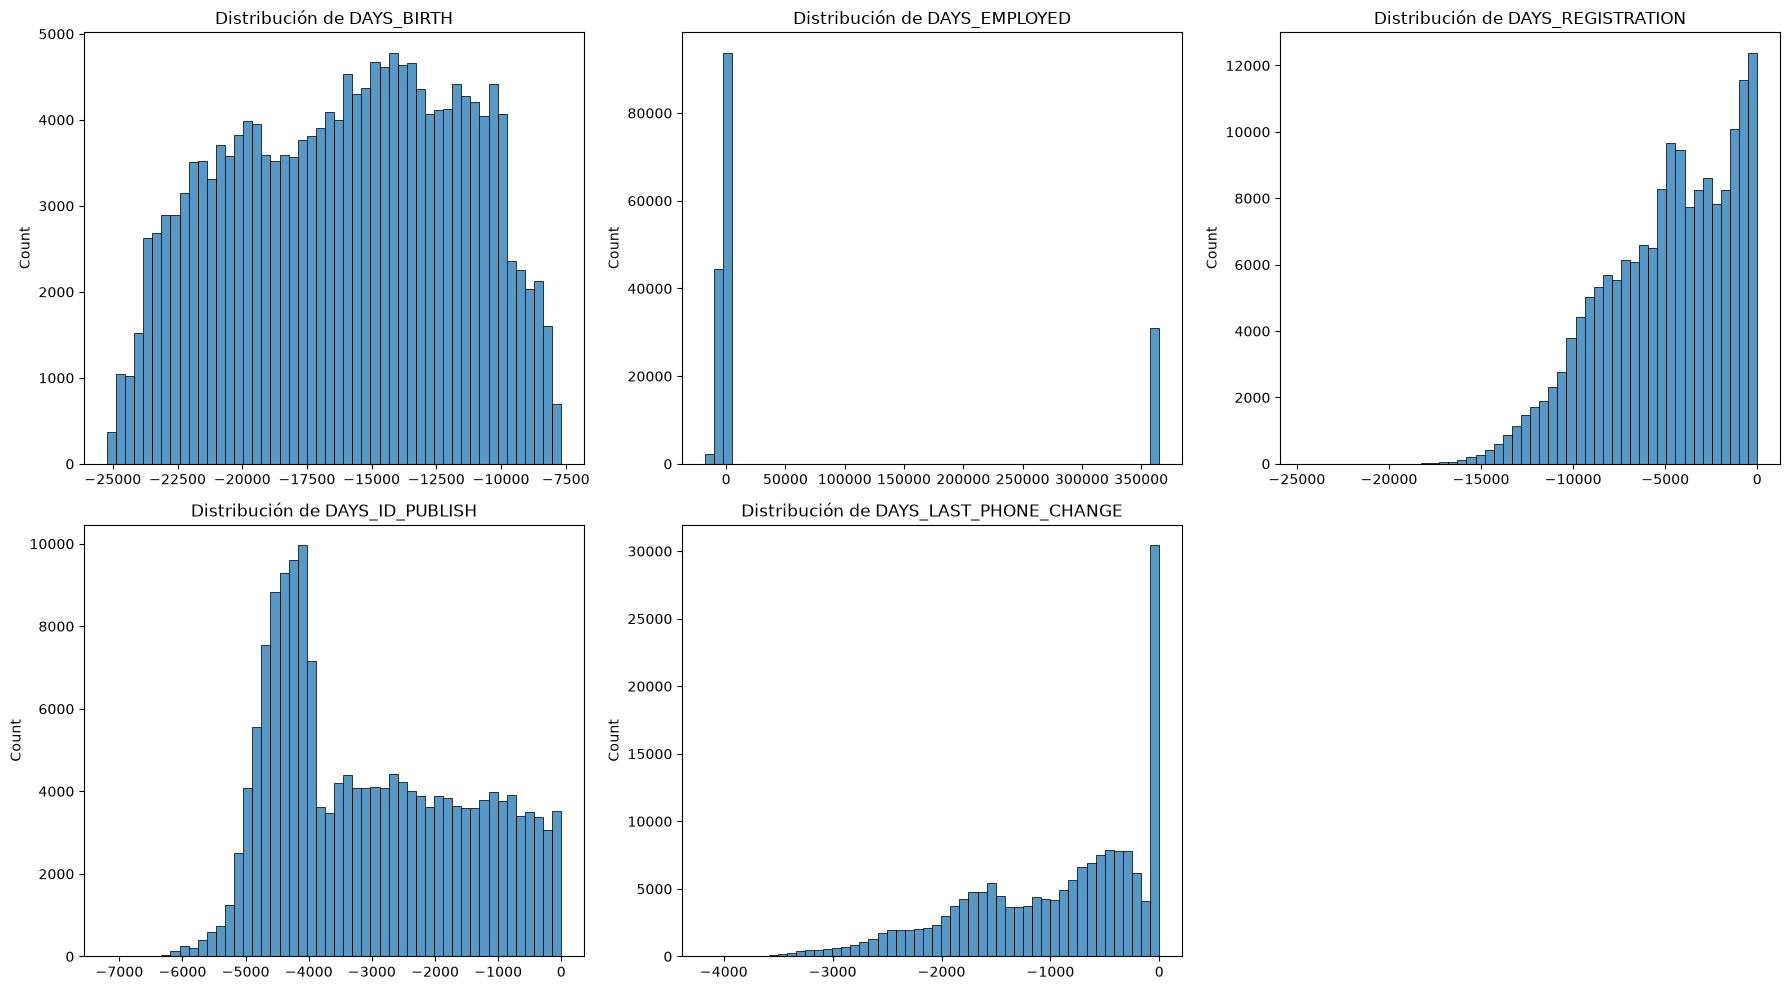

In [17]:
# Lista de variables temporales
cols_days = ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 
             'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cols_days):
    sns.histplot(data=train, x=col, bins=50, ax=axes[i])
    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel('')

# Ocultar el último gráfico vacío (5 variables en 6 espacios)
axes[5].axis('off')

plt.tight_layout()
plt.show()

##### Primera observación
Trabajar con "días negativos" dificulta mucho la validación del modelo. Convierte estas variables a años absolutos positivos multiplicando por -1 y dividiendo entre 365.25.

In [18]:
cols_days = ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']

for col in cols_days:
    # Crear nuevas columnas en años y en positivo
    train[f'{col}_IN_YEARS'] = train[col] / -365.25
    test[f'{col}_IN_YEARS'] = test[col] / -365.25

##### Segunda observación
Si introduces el valor de 365,243 en el modelo, la escala destruirá la variable de empleo. Debes extraer su significado como indicador (flag) y luego neutralizar el número.

In [19]:
# A. Crear la variable binaria que captura el significado de negocio
train['FLAG_EMPLOYED_ANOMALY'] = (train['DAYS_EMPLOYED'] > 0).astype(int)
test['FLAG_EMPLOYED_ANOMALY'] = (test['DAYS_EMPLOYED'] > 0).astype(int)

# B. Reemplazar el número absurdo por NaN en las variables originales transformadas
train['DAYS_EMPLOYED_IN_YEARS'] = train['DAYS_EMPLOYED_IN_YEARS'].replace(train['DAYS_EMPLOYED_IN_YEARS'].min(), np.nan)
test['DAYS_EMPLOYED_IN_YEARS'] = test['DAYS_EMPLOYED_IN_YEARS'].replace(test['DAYS_EMPLOYED_IN_YEARS'].min(), np.nan)

#### las 6 nuevas features que se integrarán aL modelo son:

    DAYS_BIRTH_IN_YEARS
    DAYS_EMPLOYED_IN_YEARS (con los valores anómalos convertidos a NaN)
    DAYS_REGISTRATION_IN_YEARS
    DAYS_ID_PUBLISH_IN_YEARS
    DAYS_LAST_PHONE_CHANGE_IN_YEARS
    FLAG_EMPLOYED_ANOMALY

#### Columnas AMT_REQ
Consultas a Buró de Crédito

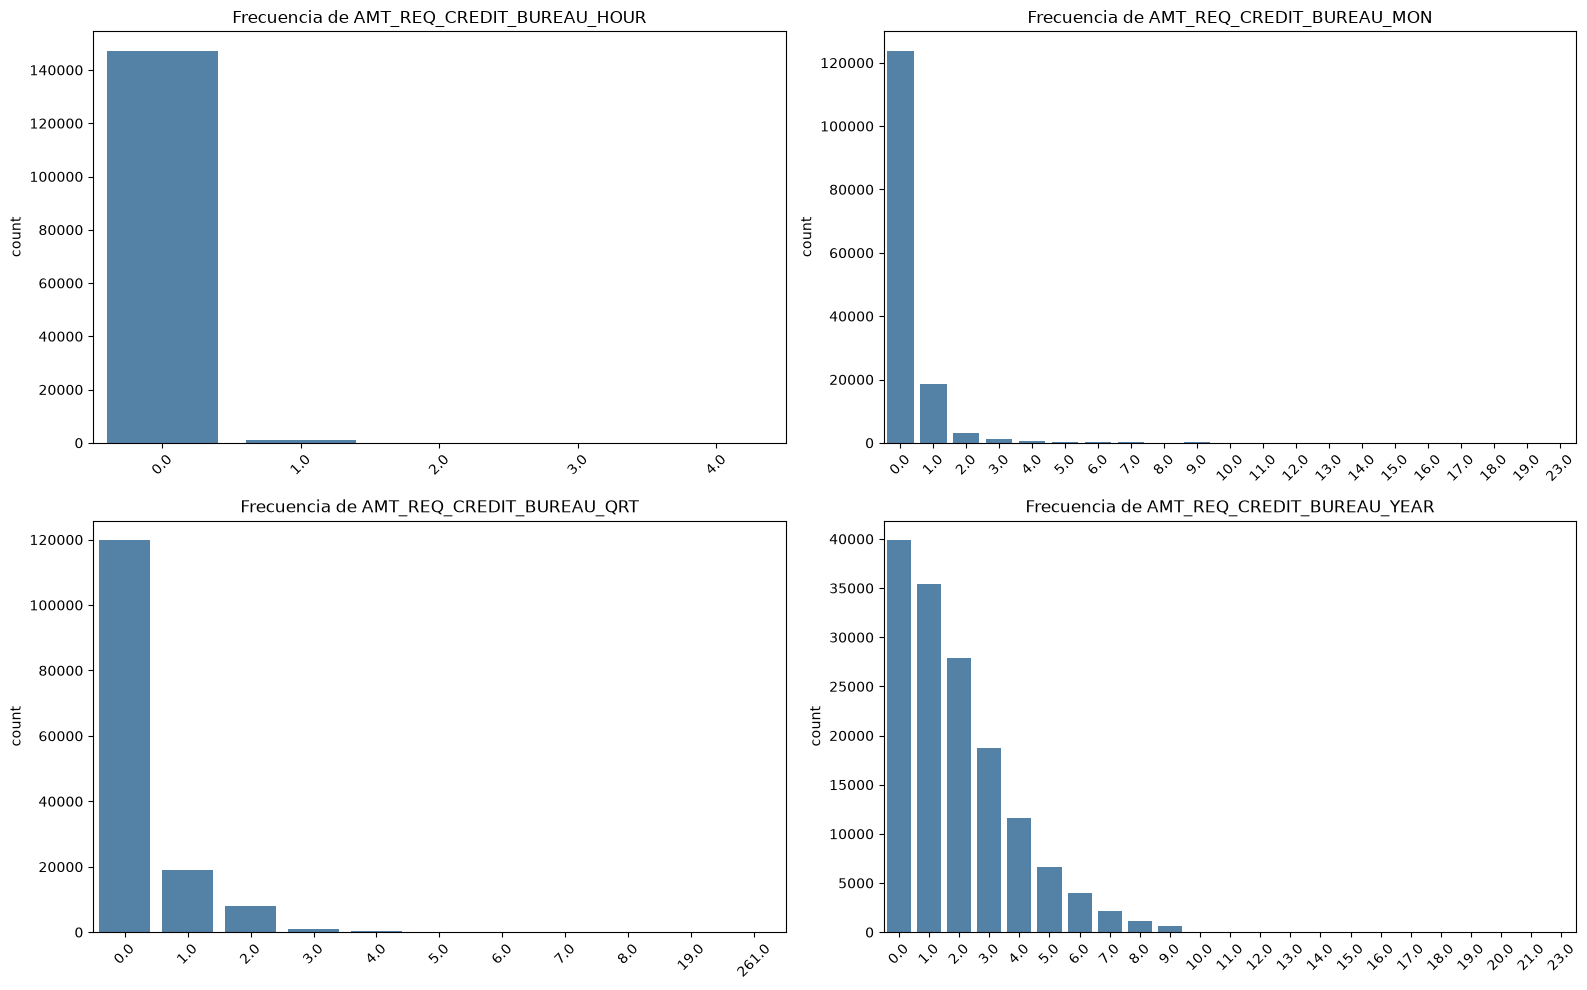

In [20]:
# Lista de consultas al buró
cols_req = ['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_MON', 
            'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cols_req):
    sns.countplot(data=train, x=col, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Frecuencia de {col}')
    axes[i].set_xlabel('')
    # Rotar etiquetas si hay muchos valores discretos
    axes[i].tick_params(axis='x', rotation=45) 

plt.tight_layout()
plt.show()

##### Primera observación
La variable AMT_REQ_CREDIT_BUREAU_QRT registra un pico anómalo con un valor de 261.0 consultas. Un registro de esta magnitud en un lapso de tres meses señala un error en la captura de datos o un comportamiento automatizado inusual.

In [21]:
#Winsorización (Clipping) del Outlier Trimestral
techo_qrt = train['AMT_REQ_CREDIT_BUREAU_QRT'].quantile(0.999)
train['AMT_REQ_CREDIT_BUREAU_QRT'] = train['AMT_REQ_CREDIT_BUREAU_QRT'].clip(upper=techo_qrt)
test['AMT_REQ_CREDIT_BUREAU_QRT'] = test['AMT_REQ_CREDIT_BUREAU_QRT'].clip(upper=techo_qrt)

##### Segunda observación
Debido a que AMT_REQ_CREDIT_BUREAU_HOUR casi no posee varianza fuera del cero, a un algoritmo como LightGBM o XGBoost le costará encontrar particiones útiles. Se transformará en una variable binaria (0 si no hubo consultas, 1 si hubo al menos una).

In [22]:
train['FLAG_REQ_BUREAU_HOUR'] = (train['AMT_REQ_CREDIT_BUREAU_HOUR'] > 0).astype(int)
test['FLAG_REQ_BUREAU_HOUR'] = (test['AMT_REQ_CREDIT_BUREAU_HOUR'] > 0).astype(int)

##### Tercera observación
En AMT_REQ_CREDIT_BUREAU_YEAR, agrupa los valores de la cola larga, como aquellos superiores a 10, en un único bloque. Esto concentra la señal estadística de los clientes que buscan crédito de forma intensiva, evitando que el modelo genere ramas muy profundas y propensas al sobreajuste para aislar frecuencias minúsculas como 19.0 o 21.0.

In [23]:
# Cualquier cliente con más de 10 consultas al año será topeado a 10
train['AMT_REQ_CREDIT_BUREAU_YEAR'] = train['AMT_REQ_CREDIT_BUREAU_YEAR'].clip(upper=10.0)
test['AMT_REQ_CREDIT_BUREAU_YEAR'] = test['AMT_REQ_CREDIT_BUREAU_YEAR'].clip(upper=10.0)
#Al hacer esto, el modelo agrupará a los perfiles de búsqueda hiperactiva en el mismo nodo de evaluación, 
#evitando sobreajustarse a las microdiferencias entre alguien que consultó 18 veces y alguien que consultó 19.

##### Cuarta observación
Un volumen total elevado de consultas antes de la solicitud suele correlacionarse fuertemente con estrés financiero, añadiendo poder predictivo adicional a tu modelo base numérico.

In [24]:
# 1. Definimos las columnas que componen el índice
cols_consultas = [
    'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR'
]

# 2. Sumamos las consultas totales por cliente
train['TOTAL_BUREAU_ENQUIRIES'] = train[cols_consultas].sum(axis=1)
test['TOTAL_BUREAU_ENQUIRIES'] = test[cols_consultas].sum(axis=1)

##### Features a integrar
    AMT_REQ_CREDIT_BUREAU_MON (Original sin cambios).
    AMT_REQ_CREDIT_BUREAU_QRT (Versión winsorizada / con tope).
    AMT_REQ_CREDIT_BUREAU_YEAR (Versión agrupada / con tope en 10).
    FLAG_REQ_BUREAU_HOUR (Nueva): Variable binaria que reemplaza a la original por horas.
    TOTAL_BUREAU_ENQUIRIES (Nueva): Índice global de estrés financiero (suma de todas las

#### Columna CNT Y HAS_CAR
Demográficas e Indicadores

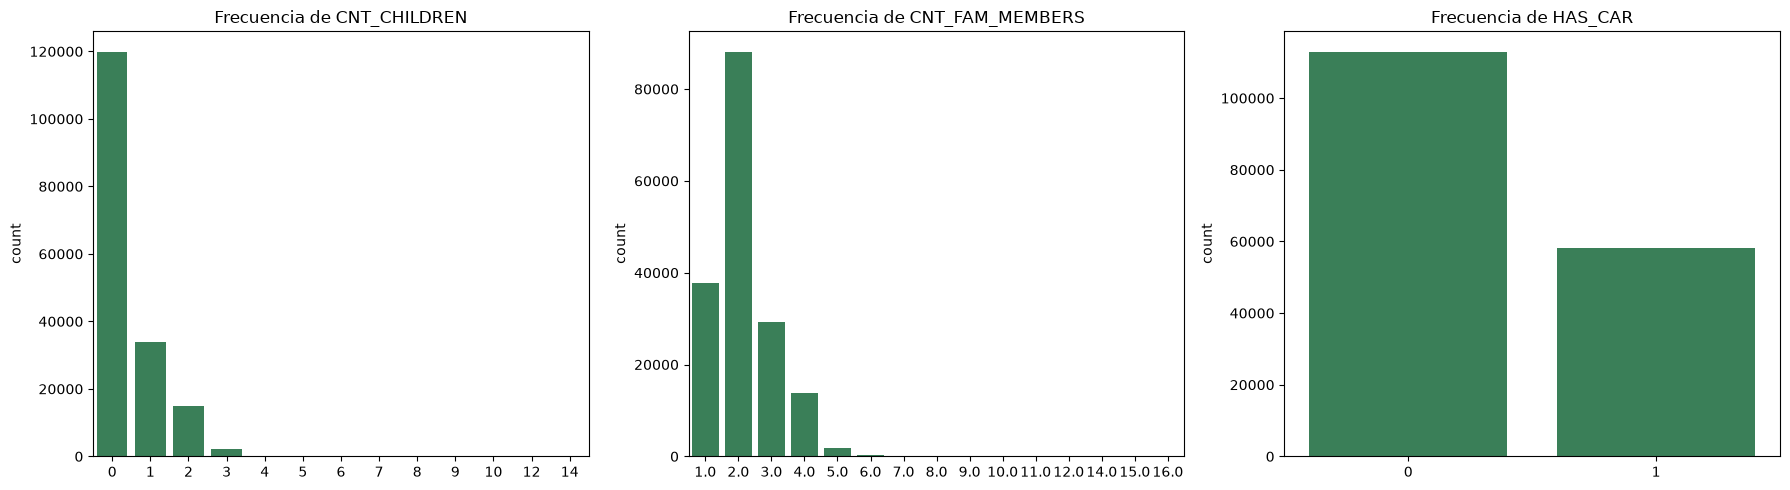

In [25]:
# Lista de variables discretas demográficas/binarias
cols_dem = ['CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'HAS_CAR']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cols_dem):
    sns.countplot(data=train, x=col, ax=axes[i], color='seagreen')
    axes[i].set_title(f'Frecuencia de {col}')
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

##### Primera observación
Las distribuciones de CNT_CHILDREN y CNT_FAM_MEMBERS presentan colas largas muy marcadas hacia la derecha, con registros anómalos que llegan hasta los 14 hijos y 16 miembros por familia.

In [29]:
train['CNT_CHILDREN_2'] = train['CNT_CHILDREN'].clip(upper=5.0)
test['CNT_CHILDREN_2'] = test['CNT_CHILDREN'].clip(upper=5.0)
train['CNT_FAM_MEMBERS_2'] = train['CNT_FAM_MEMBERS'].clip(upper=6.0)
test['CNT_FAM_MEMBERS_2'] = test['CNT_FAM_MEMBERS'].clip(upper=6.0)

##### Segunda observación
En riesgo crediticio, el ingreso total de un cliente no significa mucho si no se contextualiza con sus dependientes económicos. Dado que ya se tiene AMT_INCOME_TOTAL limpio y estabilizado, se cruzará con el tamaño de la familia para obtener el ingreso per cápita.

In [30]:
train['INCOME_PER_CAPITA'] = train['AMT_INCOME_TOTAL'] / train['CNT_FAM_MEMBERS']
test['INCOME_PER_CAPITA'] = test['AMT_INCOME_TOTAL'] / test['CNT_FAM_MEMBERS']

##### Tercera observación
Como CNT_FAM_MEMBERS agrupa a todos los habitantes del hogar, puedes derivar la cantidad de adultos restando los hijos. Esto le da a LightGBM/XGBoost una métrica directa de "aportantes potenciales" frente a "dependientes económicos" puros en el hogar.

In [31]:
train['ADULTS_IN_HOUSE'] = train['CNT_FAM_MEMBERS'] - train['CNT_CHILDREN']
test['ADULTS_IN_HOUSE'] = test['CNT_FAM_MEMBERS'] - test['CNT_CHILDREN']

##### Features a integrar:
    CNT_CHILDREN_" (Versión con tope en 5).
    CNT_FAM_MEMBERS_2 (Versión con tope en 6).
    HAS_CAR (La variable binaria que ya habías creado para aislar los NAs de los autos).
    INCOME_PER_CAPITA (Nueva): El ratio entre los ingresos y el tamaño de la familia.
    ADULTS_IN_HOUSE (Nueva): Estimación de aportantes restando los hijos a los miembros totales.

#### Columnas REGION_POPULATION_RELATIVE y OWN_CAR_AGE

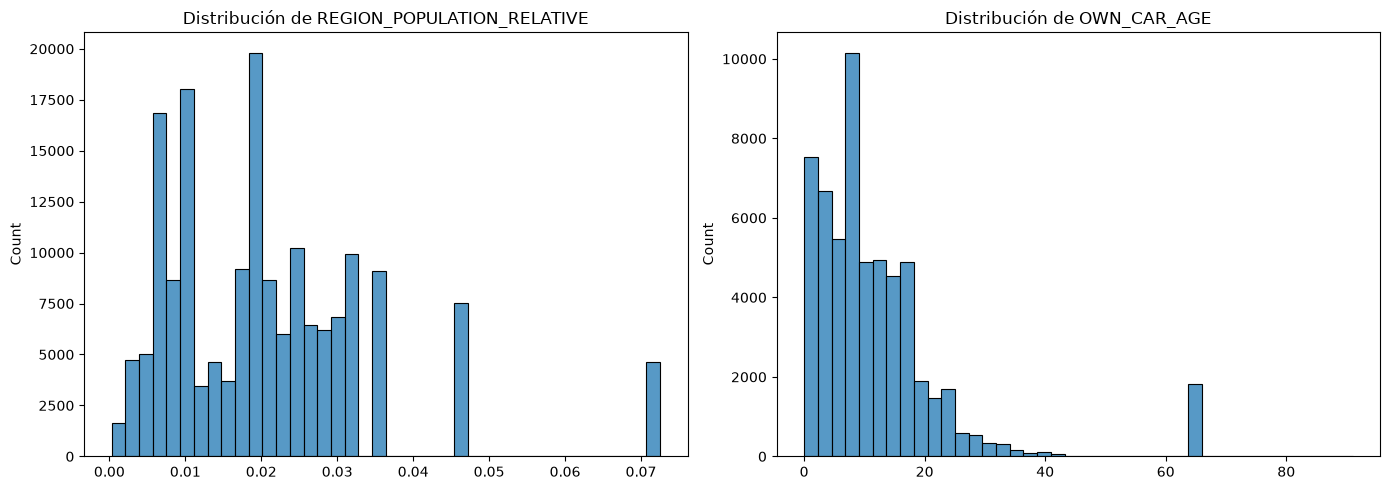

In [26]:
# Lista de variables continuas restantes
cols_misc = ['REGION_POPULATION_RELATIVE', 'OWN_CAR_AGE']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, col in enumerate(cols_misc):
    sns.histplot(data=train, x=col, bins=40, ax=axes[i])
    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

##### Primera observación
Ese pico de ~65 años destruirá la linealidad de la depreciación del vehículo. 
Conviértelo en NaN para que el algoritmo lo procese nativamente sin afectar la evaluación de los autos reales.

In [34]:
# Neutralizar edades de vehículos
train['OWN_CAR_AGE'] = np.where(train['OWN_CAR_AGE'] > 60, np.nan, train['OWN_CAR_AGE'])
test['OWN_CAR_AGE'] = np.where(test['OWN_CAR_AGE'] > 60, np.nan, test['OWN_CAR_AGE'])

### Features finales

In [37]:
final_features = [
    # 1. Variables Demográficas y Familiares
    'CNT_CHILDREN_2',               # Versión contenida (tope en 5)
    'CNT_FAM_MEMBERS_2',            # Versión contenida (tope en 6)
    'REGION_POPULATION_RELATIVE',   # Original (multimodalidad intacta)
    'INCOME_PER_CAPITA',            # Ingreso sobre total de familiares crudos
    'ADULTS_IN_HOUSE',              # Miembros totales crudos menos hijos crudos
    
    # 2. Variables Financieras (Transformadas y Ratios)
    'AMT_CREDIT_LOG',               # Logaritmo del crédito
    'AMT_ANNUITY_LOG',              # Logaritmo de la cuota
    'AMT_GOODS_PRICE_LOG',          # Logaritmo del precio del bien
    'AMT_INCOME_TOTAL_LOG',         # Logaritmo del ingreso total (previamente topeado)
    'LTV',                          # Loan-to-Value (Crédito / Precio del bien)
    'DEBT_RATIO',                   # Ratio de deuda (Cuota / Ingreso total)
    
    # 3. Variables Temporales (En años positivos)
    'DAYS_BIRTH_IN_YEARS',             
    'DAYS_EMPLOYED_IN_YEARS',       # Anomalía de 365243 convertida a NaN
    'DAYS_REGISTRATION_IN_YEARS',      
    'DAYS_ID_PUBLISH_IN_YEARS',        
    'DAYS_LAST_PHONE_CHANGE_IN_YEARS', 
    
    # 4. Puntuaciones Externas
    'EXT_SOURCE_1',                 
    'EXT_SOURCE_2',                 
    'EXT_SOURCE_3',                 
    
    # 5. Consultas al Buró de Crédito
    'AMT_REQ_CREDIT_BUREAU_MON',    
    'AMT_REQ_CREDIT_BUREAU_QRT',    # Topeada en el percentil 99.9
    'AMT_REQ_CREDIT_BUREAU_YEAR',   # Agrupada (tope en 10 consultas)
    'TOTAL_BUREAU_ENQUIRIES',       # Suma total de consultas (Índice de estrés)
    
    # 6. Activos e Indicadores Binarios (Flags)
    'OWN_CAR_AGE',                  # Continua real (Outliers > 60 convertidos a NaN)
    'HAS_CAR',                      # 1 si posee vehículo, 0 si no
    'FLAG_EMPLOYED_ANOMALY',        # 1 si tenía el error de 365243 días, 0 si no
    'FLAG_REQ_BUREAU_HOUR'          # 1 si tuvo consultas en la última hora, 0 si no
]

### Creación del primer modelo 

In [39]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, classification_report

# 1. Definir nuestras variables predictoras (X) y el objetivo (y)
X = train[final_features]
y = train['TARGET']

# 2. División Estratificada (Train y Validation)
# El stratify=y garantiza que la minoría (TARGET=1) se reparta equitativamente
X_train, X_val, y_train, y_val = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

# 3. Cálculo dinámico del peso para el desbalance
# Esto calcula cuántos ceros hay por cada uno, dándole más "peso" a los morosos
peso_clase = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Peso calculado para la clase positiva (TARGET=1): {peso_clase:.2f}\n")

# 4. Configuración del Modelo Baseline LightGBM
lgb_model = lgb.LGBMClassifier(
    objective='binary',
    metric='auc',                # Métrica reina en riesgo de crédito
    n_estimators=1500,           # Número alto de árboles (lo frenaremos con Early Stopping)
    learning_rate=0.05,          # Aprendizaje gradual y estable
    scale_pos_weight=peso_clase, # Manejo del desbalance extremo
    max_depth=6,                 # Controlar la profundidad para evitar sobreajuste inicial
    subsample=0.8,               # Usar 80% de datos por árbol (previene overfitting)
    colsample_bytree=0.8,        # Usar 80% de features por árbol
    random_state=42,
    importance_type='gain',      # Mide cuánto mejora el modelo cada vez que usa una variable
    verbose=-1
)

# 5. Entrenar con Early Stopping
# El modelo se detendrá si no mejora en el conjunto de validación durante 50 rondas
callbacks = [lgb.early_stopping(stopping_rounds=50, verbose=True)]

lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    callbacks=callbacks
)

# 6. Evaluación del Modelo
# Extraemos las probabilidades de que el cliente sea 1 (Moroso)
y_pred_proba = lgb_model.predict_proba(X_val)[:, 1]

# Calculamos el ROC AUC
auc_score = roc_auc_score(y_val, y_pred_proba)
print(f"\n=====================================================")
print(f"  ROC AUC Score del Baseline Numérico: {auc_score:.4f}")
print(f"=====================================================")

Peso calculado para la clase positiva (TARGET=1): 11.39

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[237]	training's auc: 0.808453	valid_1's auc: 0.739573

  ROC AUC Score del Baseline Numérico: 0.7396


##### Poner la predicción en el formato de envío

In [45]:
import os
from pathlib import Path
pred = lgb_model.predict_proba(test[final_features])[:, 1]
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.362259
1,171203,0.745033
2,171204,0.687390
3,171205,0.661182
4,171206,0.712271
...,...,...
61495,232697,0.658136
61496,232698,0.442197
61497,232699,0.350303
61498,232700,0.594679


In [46]:
# Crear el directorio "output" si no existe
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Especificar la ruta del nuevo archivo de salida
output_file = output_dir / "submission.csv"

# Guardar el archivo CSV en el directorio "output"
sample_sub.to_csv(output_file, index=False)